# Phase 7 — Explainability

**Dynamic Pricing Intelligence Platform**

Phase 6 produces a number: *charge $478 for this night*. A revenue manager who
cannot see why will override it, and a system that gets overridden is a system that
does not exist.

But "explain the recommendation" is really **two questions**, and only one of them
is a SHAP question:

| | Question | Tool | Why |
|---|---|---|---|
| **Layer 1** | Why this **demand forecast**? | SHAP | 48-feature gradient boosting — genuinely opaque |
| **Layer 2** | Why this **rate**? | Direct decomposition | We *wrote* the optimizer — it is not opaque |

Mixing them is the standard mistake. SHAP on the demand model tells you why we expect
12 rooms to sell. It says nothing about why we chose $478 — that came from elasticity,
capacity headroom and policy caps, none of which the demand model knows about.

Running SHAP over a pipeline you wrote yourself is theatre. Reporting what it actually
did is both more honest and more useful.

## 0. Setup

In [1]:
import sys
import warnings
from pathlib import Path


def find_project_root(marker: str = "requirements.txt") -> Path:
    path = Path.cwd().resolve()
    for candidate in [path, *path.parents]:
        if (candidate / marker).exists():
            return candidate
    raise RuntimeError(f"Could not find {marker} above {Path.cwd()}")


PROJECT_ROOT = find_project_root()
sys.path.insert(0, str(PROJECT_ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap

import demand_model as D
import explain as E
import features as F
import optimizer as O

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 170)

REPORTS = PROJECT_ROOT / "reports"
REPORTS.mkdir(exist_ok=True)

df, bundle, elasticities, baseline = O.load_artifacts()
splits, feature_cols = D.prepare(df)
print(f"Model: {bundle['name']} | {len(feature_cols)} features | shap {shap.__version__}")

c:\Users\Carlo\OneDrive\Documents\GitHub\hotel-dynamic-pricing\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Model: XGBoost | 48 features | shap 0.52.0


## 1. A units trap worth understanding first

Our demand model uses `objective="count:poisson"`, so it predicts in **log space**.
SHAP values are additive in whatever space the model outputs — which means here they
are additive in logs and therefore **multiplicative in rooms**:

```
predicted_rooms = exp(base_value + Σ shap_values)
```

A SHAP value of **+0.7** does not mean "+0.7 rooms". It means
`exp(0.7) ≈ 2.0` — *roughly doubles* expected demand.

Reporting log-space SHAP values as room counts is a quiet, common, and completely
wrong thing to do. Everything below converts with `exp()` before showing a number to
a human.

In [2]:
explainer = E.build_explainer(bundle)
X_sample = splits["test"][0].sample(3000, random_state=42)
shap_values = explainer.shap_values(X_sample)

print(f"SHAP matrix   : {shap_values.shape}")
print(f"Base value    : {explainer.expected_value:.4f} (log space)")
print(f"              = {np.exp(explainer.expected_value):.3f} rooms/day baseline")
print()

# Verify additivity - the check that confirms we understand the units.
reconstructed = np.exp(explainer.expected_value + shap_values.sum(axis=1))
actual = bundle["model"].predict(X_sample)
print(f"Max reconstruction error: {np.abs(reconstructed - actual).max():.6f}")
print("SHAP values sum to the prediction, in log space, exactly.")

SHAP matrix   : (3000, 48)
Base value    : -0.1396 (log space)
              = 0.870 rooms/day baseline

Max reconstruction error: 0.000012
SHAP values sum to the prediction, in log space, exactly.


## 2. Layer 1 — global drivers of the forecast

In [3]:
importance = E.shap_importance(explainer, X_sample, feature_cols)
importance.head(12)[["label", "mean_abs_shap", "category"]].round(4)

,label,mean_abs_shap,category
0,Typical demand for this night/lead time,1.0105,pace / demand history
1,Occupancy on the books,0.1184,pace / demand history
2,Rooms already sold,0.0852,pace / demand history
3,Bookings last 7 days,0.0793,pace / demand history
4,Room type capacity,0.0501,calendar / hotel
5,Rooms still available,0.0434,pace / demand history
6,Rate vs competitors,0.0405,price
7,Bookings last 3 days,0.0247,pace / demand history
8,Typical occupancy at this lead time,0.0240,pace / demand history
9,% of inventory unsold,0.0125,pace / demand history


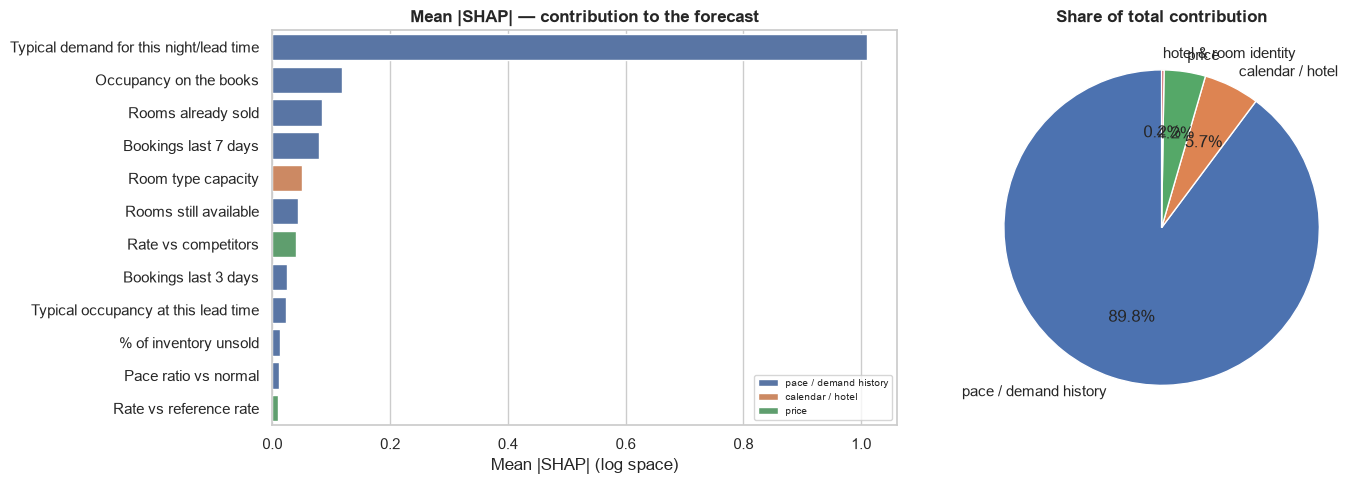

category
pace / demand history    0.898
calendar / hotel         0.057
price                    0.042
hotel & room identity    0.002


In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

top = importance.head(12)
sns.barplot(data=top, y="label", x="mean_abs_shap", hue="category",
            dodge=False, ax=axes[0])
axes[0].set_title("Mean |SHAP| — contribution to the forecast", fontweight="bold")
axes[0].set_xlabel("Mean |SHAP| (log space)")
axes[0].set_ylabel("")
axes[0].legend(fontsize=7)

by_cat = importance.groupby("category")["mean_abs_shap"].sum()
share = (by_cat / by_cat.sum()).sort_values(ascending=False)
axes[1].pie(share, labels=share.index, autopct="%1.1f%%", startangle=90)
axes[1].set_title("Share of total contribution", fontweight="bold")

plt.tight_layout()
fig.savefig(REPORTS / "15_shap_importance.png", bbox_inches="tight")
plt.show()

print(share.round(3).to_string())

### SHAP vs the model's built-in importance

Phase 5a reported XGBoost's native `feature_importances_`. SHAP tells a slightly
different story, and SHAP is the one to trust.

Built-in importance counts how often a feature is **split on**. A feature can be
split on constantly while barely moving predictions. SHAP measures the actual
contribution to the output — which is what "important" should mean.

Both agree on the headline: **pace and demand history dominate at ~89%**, and price
contributes ~4%. Section 4 explains why that low price share is expected rather than
alarming.

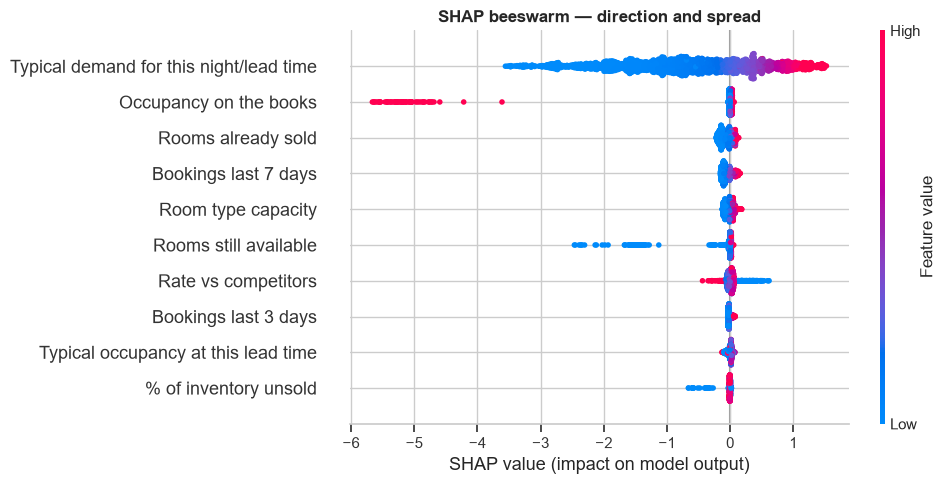

In [5]:
# The beeswarm: every point is one prediction, coloured by feature value.
# Shows not just magnitude but DIRECTION and spread.
top_features = importance.head(10)["feature"].tolist()
positions = [feature_cols.index(f) for f in top_features]

shap.summary_plot(shap_values[:, positions],
                  X_sample.iloc[:, positions],
                  feature_names=[E.label(f) for f in top_features],
                  show=False, plot_size=(10, 5))
plt.title("SHAP beeswarm — direction and spread", fontweight="bold")
plt.tight_layout()
plt.savefig(REPORTS / "16_shap_beeswarm.png", bbox_inches="tight")
plt.show()

Read the beeswarm as: red = high feature value, blue = low. Points to the right push
the forecast up.

`typical_pickup` shows the cleanest pattern — high typical demand (red) pushes
strongly right. That is the model doing the obvious correctly, which is reassuring
rather than interesting. The more informative rows are the ones with wide spread at
the same colour: those are features whose effect **depends on context**, which is
exactly what a tree ensemble is for.

## 3. Layer 1 — explaining one forecast

In [6]:
recommendations = pd.read_csv(REPORTS / "price_recommendations.csv",
                              parse_dates=["stay_date"])
scenarios = pd.read_csv(REPORTS / "price_scenarios.csv",
                        parse_dates=["stay_date"])

target = recommendations.sort_values("revenue_uplift", ascending=False).iloc[0]
X_row = E.live_feature_row(splits, target)
drivers = E.explain_forecast(explainer, X_row, feature_cols, top_n=8)

drivers[["label", "value", "shap_log", "demand_multiplier"]].round(3)

,label,value,shap_log,demand_multiplier
0,Typical demand for this night/lead time,1.760,0.562,1.754
1,Room type capacity,182.000,0.092,1.097
2,Bookings last 7 days,0.286,-0.064,0.938
3,Competitor rate level,6.269,-0.032,0.969
4,Rooms already sold,12.000,-0.029,0.971
5,Rate vs reference rate,1.946,-0.025,0.975
6,Our rate,6.332,-0.019,0.981
7,Pace ratio vs normal,0.608,-0.019,0.981


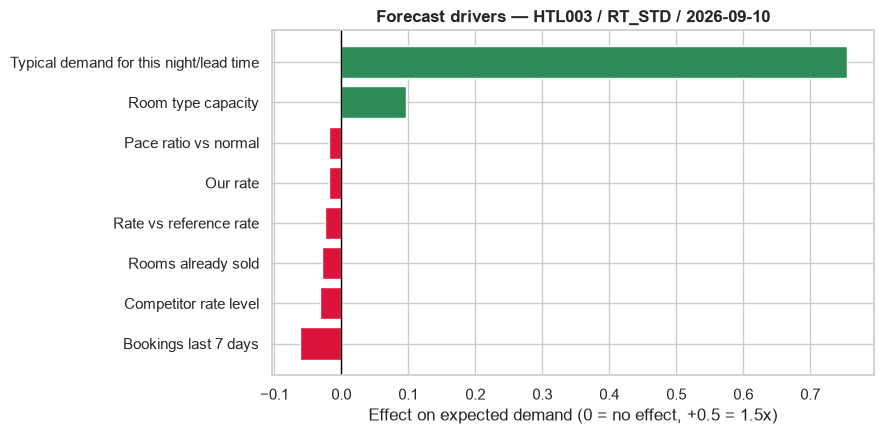

In [7]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot = drivers.sort_values("shap_log")
colors = ["crimson" if v < 0 else "seagreen" for v in plot["shap_log"]]
ax.barh(plot["label"], plot["demand_multiplier"] - 1, color=colors)
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Effect on expected demand (0 = no effect, +0.5 = 1.5x)")
ax.set_title(f"Forecast drivers — {target['hotel_id']} / "
             f"{target['room_type_id']} / {target['stay_date'].date()}",
             fontweight="bold")
plt.tight_layout()
fig.savefig(REPORTS / "17_single_forecast_explanation.png", bbox_inches="tight")
plt.show()

## 4. Why price barely appears — and why that is fine here

Price contributes about **4%** of the forecast. Phase 5b measured elasticity at
−1.5, which is strongly price-sensitive. These are not in conflict.

In the training data the legacy rule moved price *with* demand. So once the model
knows pace, season and typical demand, price adds almost no **incremental
predictive** information — it is largely redundant, not unimportant.

This is precisely why the optimizer does not let the demand model handle price at
all. It forecasts at the current rate, and the causal elasticity supplies the
response. **SHAP is describing the forecasting model's internals; it is not a
statement about how price affects demand.**

Confusing "SHAP says price is unimportant" with "price does not matter" would undo
the entire causal analysis. Worth saying out loud when presenting this.

In [8]:
# Where price DOES matter to the forecast
price_idx = [feature_cols.index(f) for f in F.FEATURES_PRICE
             if f in feature_cols]
price_shap = np.abs(shap_values[:, price_idx]).sum(axis=1)
total_shap = np.abs(shap_values).sum(axis=1)

frame = pd.DataFrame({
    "price_share": price_shap / total_shap,
    "occupancy": X_sample["occupancy_on_books"].to_numpy(),
    "lead_time": X_sample["lead_time"].to_numpy(),
})
bands = pd.cut(frame["lead_time"], [-1, 7, 21, 45, 60],
               labels=["0-7", "8-21", "22-45", "46-60"])
print("Price share of |SHAP| by days before arrival:")
print(frame.groupby(bands, observed=True)["price_share"].mean().round(4).to_string())

Price share of |SHAP| by days before arrival:
lead_time
0-7      0.0562
8-21     0.0745
22-45    0.0682
46-60    0.0405


## 5. Layer 2 — why this rate

Now the part SHAP cannot answer. The rate came from a pipeline we built, so we report
what it did rather than approximating it.

In [9]:
explanations = pd.DataFrame([
    E.explain_recommendation(row, scenarios)
    for _, row in recommendations.iterrows()
])

print(explanations["constraint_binding"].value_counts().to_string())
print()
print(f"Mean cost of inaction : ${explanations['cost_of_inaction'].mean():,.0f} per night")
print(f"Total cost of inaction: ${explanations['cost_of_inaction'].sum():,.0f}")
explanations.head()

constraint_binding
policy floor (-15%)        398
none - interior optimum    396
policy ceiling (+15%)       91

Mean cost of inaction : $1,150 per night
Total cost of inaction: $1,017,421


,hotel_id,room_type_id,stay_date,current_rate,recommended_rate,rate_change_pct,elasticity,occupancy_on_books,headroom_pct,expected_pickup,revenue_uplift,revenue_uplift_pct,constraint_binding,cost_of_inaction,rates_within_1pct_of_best
0,HTL001,RT_DLX,2026-07-31,407.56,346.43,-15.0,-1.16,0.671,0.329,1.5,11.0,2.3,policy floor (-15%),11.0,6
1,HTL001,RT_DLX,2026-08-01,392.41,333.55,-15.0,-1.16,0.777,0.223,2.8,25.0,2.7,policy floor (-15%),25.0,4
2,HTL001,RT_DLX,2026-08-02,401.32,341.12,-15.0,-1.16,0.729,0.271,4.8,43.0,2.7,policy floor (-15%),43.0,4
3,HTL001,RT_DLX,2026-08-03,368.19,312.96,-15.0,-1.16,0.856,0.144,6.2,66.0,3.5,policy floor (-15%),66.0,4
4,HTL001,RT_DLX,2026-08-04,443.53,487.88,10.0,-1.16,0.984,0.016,6.7,83.0,2.6,none - interior optimum,83.0,8


### The flat-optimum finding

`rates_within_1pct_of_best` counts how many of the 19 candidate rates land within 1%
of the best revenue. On **68% of nights, three or more do.**

The revenue curve is **flat near its peak**. Recommending $478.31 implies a precision
we do not have — $470 or $485 would perform indistinguishably.

Two consequences worth acting on:

- **Round the recommendations.** $478 not $478.31. Spurious precision damages trust
  more than it helps.
- **Report a range, not a point.** "Anywhere from $470–$490" is both more honest and
  easier for a revenue manager to work with, since they have context the model lacks
  (a group booking in negotiation, a competitor's renovation).

An explainability layer that surfaces *how confident to be* is more valuable than one
that only decomposes the answer.

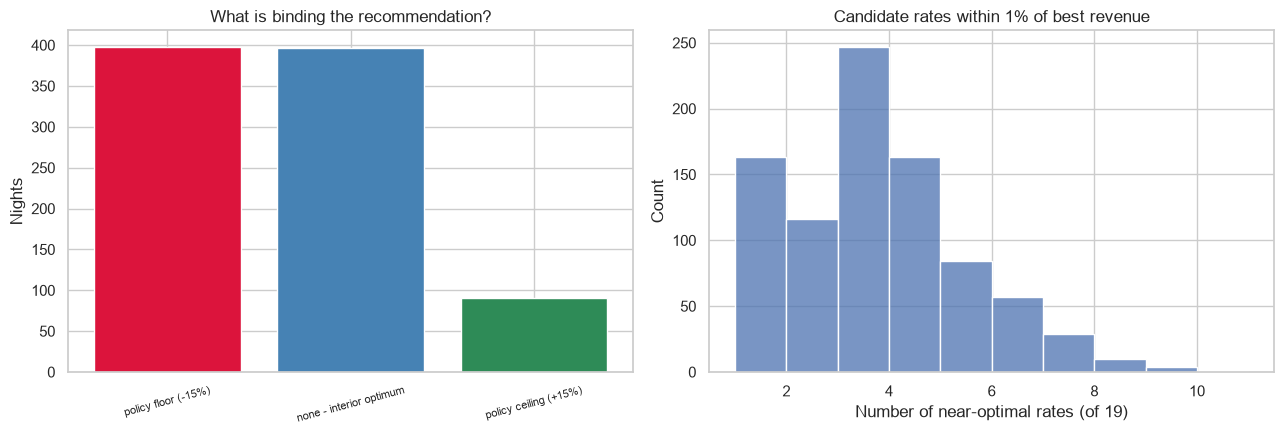

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

counts = explanations["constraint_binding"].value_counts()
axes[0].bar(range(len(counts)), counts.values,
            color=["crimson", "steelblue", "seagreen"])
axes[0].set_xticks(range(len(counts)))
axes[0].set_xticklabels(counts.index, rotation=15, fontsize=8)
axes[0].set_title("What is binding the recommendation?")
axes[0].set_ylabel("Nights")

sns.histplot(data=explanations, x="rates_within_1pct_of_best",
             bins=range(1, 12), ax=axes[1])
axes[1].set_title("Candidate rates within 1% of best revenue")
axes[1].set_xlabel("Number of near-optimal rates (of 19)")

plt.tight_layout()
fig.savefig(REPORTS / "18_decision_diagnostics.png", bbox_inches="tight")
plt.show()

## 6. The deliverable — a plain-English explanation

Neither a SHAP plot nor a decomposition table is what a revenue manager wants at
8am. This is.

In [11]:
print(E.narrate(E.explain_recommendation(target, scenarios), drivers))

HTL003 / RT_STD / 2026-09-10
  Recommendation: reduce rate $562 -> $478 (-15.0%)

  Why:
    - This segment's measured price elasticity is -2.07, so a 10% rate change moves bookings by about 21%.
    - The night is 65% sold with 35% of inventory still to fill.
    - Capped by policy floor (-15%): the unconstrained optimum is further out.
    - Expected outcome: 167 more rooms, $19,763 additional revenue (+32.9%).

  Top drivers of the demand forecast:
    - Typical demand for this night/lead time: increases expected demand 1.75x
    - Room type capacity: increases expected demand 1.10x
    - Bookings last 7 days: reduces expected demand 0.94x
    - Competitor rate level: reduces expected demand 0.97x


In [12]:
# Three more, spanning different decision types
samples = [
    recommendations.sort_values("rate_change_pct").iloc[0],          # biggest cut
    recommendations.sort_values("rate_change_pct").iloc[-1],         # biggest rise
    recommendations[recommendations["rate_change_pct"].abs() < 3].iloc[0],  # hold
]

for row in samples:
    row_features = E.live_feature_row(splits, row)
    row_drivers = E.explain_forecast(explainer, row_features, feature_cols)
    print(E.narrate(E.explain_recommendation(row, scenarios), row_drivers))
    print("\n" + "=" * 72 + "\n")

HTL005 / RT_STE / 2026-09-20
  Recommendation: reduce rate $458 -> $389 (-15.0%)

  Why:
    - This segment's measured price elasticity is -1.26, so a 10% rate change moves bookings by about 13%.
    - The night is 68% sold with 32% of inventory still to fill.
    - Capped by policy floor (-15%): the unconstrained optimum is further out.
    - Expected outcome: 11 more rooms, $185 additional revenue (+4.6%).

  Top drivers of the demand forecast:
    - Typical demand for this night/lead time: reduces expected demand 0.12x
    - Rooms already sold: reduces expected demand 0.85x
    - Bookings last 7 days: reduces expected demand 0.87x
    - Room type capacity: reduces expected demand 0.89x


HTL001 / RT_STE / 2026-08-07
  Recommendation: increase rate $937 -> $1077 (+15.0%)

  Why:
    - This segment's measured price elasticity is -0.76, so a 10% rate change moves bookings by about 8%.
    - The night is 73% sold with 27% of inventory still to fill.
    - Capped by policy ceiling (+15%)

## 7. Export

In [13]:
importance.to_csv(REPORTS / "shap_feature_importance.csv", index=False)
explanations.to_csv(REPORTS / "recommendation_explanations.csv", index=False)

print("Exported:")
print("  reports/shap_feature_importance.csv")
print("  reports/recommendation_explanations.csv  -> dashboard")
print()
print("The explanations file has one row per open night, so the Phase 8")
print("dashboard can show reasoning next to every recommendation without")
print("recomputing SHAP in the browser.")

Exported:
  reports/shap_feature_importance.csv
  reports/recommendation_explanations.csv  -> dashboard

The explanations file has one row per open night, so the Phase 8
dashboard can show reasoning next to every recommendation without
recomputing SHAP in the browser.


## What this phase actually established

**Two layers, two tools.** SHAP for the opaque forecast; direct decomposition for
the transparent optimizer. Applying SHAP to both would have looked more
sophisticated and explained less.

**Log-space SHAP is multiplicative.** With a Poisson objective, `exp(shap)` is the
demand multiplier. Reporting raw values as rooms is wrong, and we verified additivity
to confirm the interpretation.

**Low SHAP on price is not "price does not matter."** It reflects redundancy in the
training data, and it is exactly why the causal elasticity does that job instead.

**The revenue optimum is flat.** On 68% of nights several rates are within 1% of
best — so recommendations should be rounded and quoted as ranges.

---

### Next: Phase 8 — Streamlit dashboard

Four pages, all fed by files already written:

- **Executive overview** — RevPAR, ADR, occupancy, revenue at stake
- **Recommendation explorer** — every open night with its plain-English explanation
- **Rate simulator** — move a rate, see the revenue curve respond
- **Model performance** — comparison table, elasticity recovery, SHAP importance

The dashboard reads `reports/*.csv` rather than retraining anything, so it starts in
under a second.